In [ ]:
# Initialize Markov Decision Process model
actions = (0, 1)  # actions (0=left, 1=right)
states = (0, 1, 2, 3, 4)  # states (tiles)
rewards = [-1, -1, 10, -1, -1]  # Direct rewards per state
gamma = 0.9  # discount factor
delta = 10  # Error tolerance
# Transition probabilities per state-action pair
probs = [
    [[0.9, 0.1], [0.1, 0.9], [0, 0], [0, 0], [0, 0]],
    [[0.9, 0.1], [0, 0], [0.1, 0.9], [0, 0], [0, 0]],
    [[0, 0], [0, 0], [0, 0], [0, 0], [0, 0]],  # Terminating state (all probs 0)
    [[0, 0], [0, 0], [0.9, 0.1], [0, 0], [0.1, 0.9]],
    [[0, 0], [0, 0], [0, 0], [0.9, 0.1], [0.1, 0.9]],
]

# Set policy iteration parameters
max_policy_iter = 10000  # Maximum number of policy iterations
max_value_iter = 10000  # Maximum number of value iterations
pi = [0 for s in states]
V = [0 for s in states]


# some hints:
# probs[3][2][0] : transtion probability : state 3 -> state 2 by choosing action left = 0.9
# probs[3][2][1] : transtion probability : state 3 -> state 2 by choosing action right = 0.1
# probs[1][3][0] : transtion probability : state 1 -> state 3 by choosing action right = 0
# probs[1][3][0] : transtion probability : state 1 -> state 3 by choosing action left = 0
# probs[0][0][0] : transtion probability : state 1 -> state 1 by choosing action left = 0.9
# probs[0][0][1] : transtion probability : state 1 -> state 1 by choosing action left = 0.1

# probs[s][s_next][pi[s]] : transtion probability : current state -> next state by choosing the action suggested by policy pi


for i in range(max_policy_iter):
    # Initial assumption: policy is stable
    optimal_policy_found = True

    # Policy evaluation
    # Compute value for each state under current policy
    for j in range(max_value_iter):
        max_diff = 0  # Initialize max difference
        V_new = [0, 0, 0, 0, 0]  # Initialize values
        for s in states:

            # Compute state value
            val = rewards[s]  # Get direct reward
            for s_next in states:
                val += gamma * probs[s][s_next][pi[s]] * V[s_next] # Add discounted downstream values

            # Update maximum difference
            max_diff = max(max_diff, abs(val - V[s]))

            V[s] = val  # Update value with highest value
        # If diff smaller than threshold delta for all states, algorithm terminates
        if max_diff < delta:
            break

    # Policy iteration
    # With updated state values, improve policy if needed
    for s in states:

        val_max = V[s]
        for a in actions:
            val = rewards[s]  # Get direct reward
            for s_next in states:
                val += gamma * probs[s][s_next][a] * V[s_next] # Add discounted downstream values

            # Update policy if (i) action improves value and (ii) action different from current policy
            if val > val_max and pi[s] != a:
                pi[s] = a
                val_max = val
                optimal_policy_found = False # True or False?

    # If policy did not change, algorithm terminates
    if optimal_policy_found:
        break

In [18]:
pi

[1, 1, 0, 0, 0]

### Exercise 4.8 – Analysis of the Optimal Policy in the Gambler’s Problem

The optimal policy looks odd because the goal is to maximize the chance of reaching 100, not expected profit. At 50, going all-in gives the highest chance to win in one step. But at 51, the gambler already has an advantage, so betting less reduces the risk of losing everything. The irregular pattern comes from points where certain bets can jump exactly to 100.

### Exercise 4.9 – Implementation of Value Iteration for the Gambler’s Problem

In [13]:
import numpy as np
import matplotlib.pyplot as plt


def value_iteration(p_h, theta=1e-9):
    V = np.zeros(101)
    V[100] = 1.0

    policy = np.zeros(101, dtype=int)

    while True:
        delta = 0
        for s in range(1, 100):
            actions = range(1, min(s, 100 - s) + 1)
            values = []
            for a in actions:
                values.append(p_h * V[s + a] + (1 - p_h) * V[s - a])
            best = max(values)
            delta = max(delta, abs(best - V[s]))
            V[s] = best
        if delta < theta:
            break

    for s in range(1, 100):
        actions = range(1, min(s, 100 - s) + 1)
        action_values = [p_h * V[s + a] + (1 - p_h) * V[s - a] for a in actions]
        policy[s] = actions[np.argmax(action_values)]

    return V, policy


def policy_iteration(p_h, theta=1e-9):
    V = np.zeros(101)
    V[100] = 1.0
    policy = np.ones(101, dtype=int)

    stable = False
    while not stable:
        # Policy evaluation
        while True:
            delta = 0
            for s in range(1, 100):
                a = policy[s]
                v = p_h * V[s + a] + (1 - p_h) * V[s - a]
                delta = max(delta, abs(v - V[s]))
                V[s] = v
            if delta < theta:
                break

        # Policy improvement
        stable = True
        for s in range(1, 100):
            old_action = policy[s]
            actions = range(1, min(s, 100 - s) + 1)
            action_values = [p_h * V[s + a] + (1 - p_h) * V[s - a] for a in actions]
            policy[s] = actions[np.argmax(action_values)]
            if old_action != policy[s]:
                stable = False

    return V, policy


def plot_policy(policy, title):
    plt.figure(figsize=(10, 4))
    plt.bar(range(1, 100), policy[1:100])
    plt.xlabel("Capital")
    plt.ylabel("Stake")
    plt.title(title)
    plt.show()

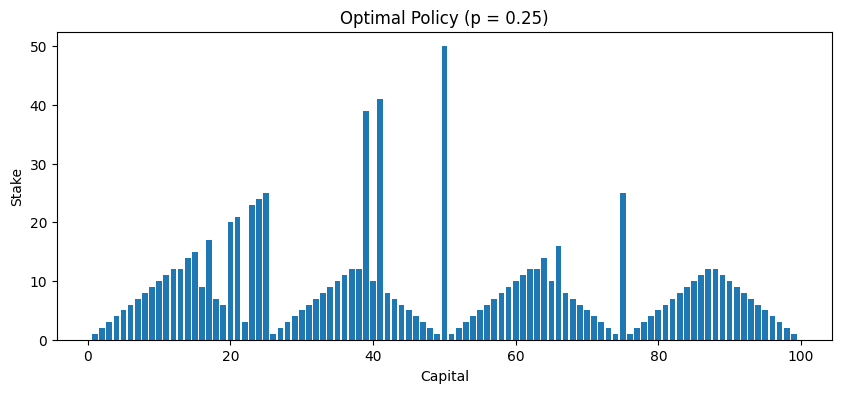

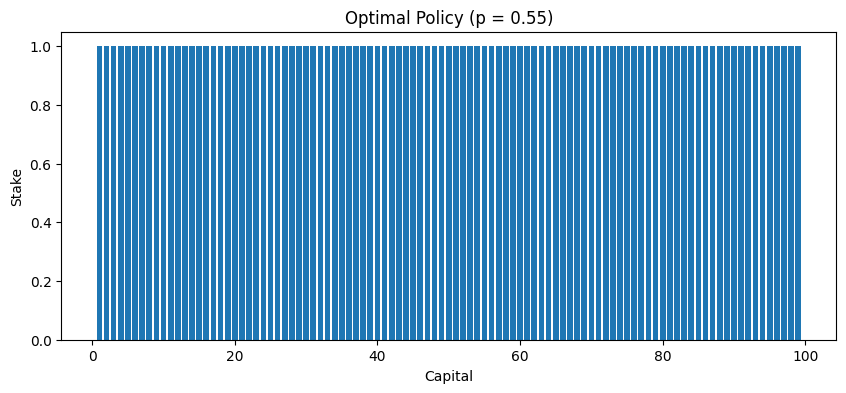

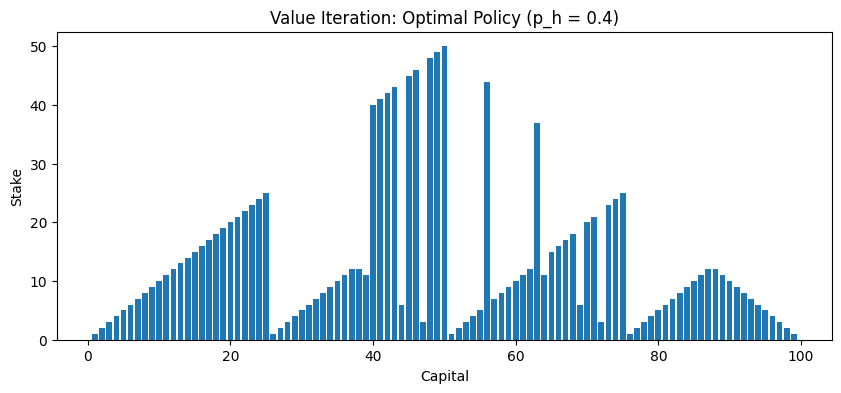

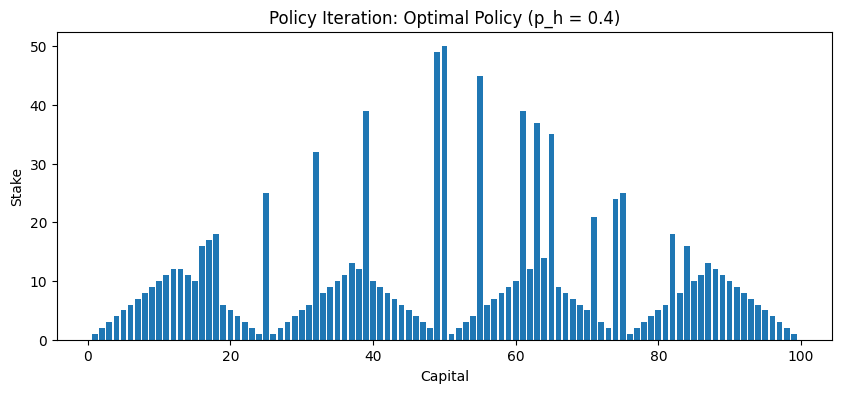

Value functions equal (p=0.4): True
Policies exactly identical: False


In [28]:
# p = 0.25
V25, pi25 = value_iteration(0.25)
plot_policy(pi25, "Optimal Policy (p = 0.25)")

# p = 0.55
V55, pi55 = value_iteration(0.55)
plot_policy(pi55, "Optimal Policy (p = 0.55)")

# Verification for p = 0.4
Vv, piv = value_iteration(0.4)
plot_policy(piv, "Value Iteration: Optimal Policy (p_h = 0.4)")
Vp, pip = policy_iteration(0.4)
plot_policy(pip, "Policy Iteration: Optimal Policy (p_h = 0.4)")

print("Value functions equal (p=0.4):", np.allclose(Vv, Vp, atol=1e-8))
print("Policies exactly identical:", np.all(piv == pip))